## FAIR Workflow
Preston Stover - September 2026

Set up a reproducible workflow containing at least the following:
- Descriptive text and explanations, e.g. markdown. This should detail how others can use and run your workflow. Specify requirements. Equations using LaTeX math are encouraged.
- Code cells, e.g. Python, R, or some other language.
- Output cells with e.g. figures, tables, and/or other elements.
For your particular setup, specify dependencies and version pinning. For conda this would e.g. be an environment.yml file, or a pyproject.toml file in uv, but it depends on the system you are using. Motivate your choice of version pinning and add a risk assessment for future package breaking.
Place your workflow in a repository, e.g. github, gitlab or elsewhere. Add as much relevant metadata as possible in the form of keywords, license, README etc.
In the notebook, add a section where you discuss how your workflow relates to FAIR data principles.

#### Tips:
- If using CoLab, packages are installed with the pip command. You can enforce specific versions as described here. This is an alterntive to using environment files which are not readily understood by CoLab.
- For information about uv / pyproject.toml, see here.
- For information about conda environments, see here.
- For information about pip environments, see here. For information about using this in CoLab, see here.

## Lattice and Simulation Functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from scipy.special import ellipk

# Lattice Functions:
def lattice(L, q, hot=True):
    '''q number of spins with value s=(1,...,q) in an LxL lattice stored as flat list.
    np.int8 is faster data type for lattice values.'''
    # hot start:
    if hot == True:
        return np.random.randint(1, q + 1, size=(L*L), dtype=np.int8)
    # cold start:
    random_state = np.random.randint(1, q + 1)
    return np.full((L*L), random_state, dtype=np.int8)

def neighbors_index(L):
    '''calculates an index of all (4) neighbor ids for each index site N in the lattice.
    Allows for direct neighbors_index[site] lookup for any point on lattice.
    np.int32 allows for L = 46 000 and N = 2 billion while being efficient.
    Using % for four directions wraps around edges of lattice (periodic).'''
    N = L**2
    # create empty index with 4 values (set to 0) corresponding to each index site N:
    neighbors = np.zeros((N, 4), dtype=np.int32)
    for i in range(N):
        # remainder gives column value and floor division gives row value of L*L matrix in N-site index:
        x = i // L  # row 
        y = i % L   # column   a%b = a − (b * (a // b))
        up = (((x-1) % L) * L) + y
        down = ((x + 1) % L) * L + y
        left = x * L + ((y - 1) % L)
        right = x * L + ((y + 1) % L)
        neighbors[i] = [up, down, left, right] # assign 4 directions' neighbor index IDs for each index site N
    return neighbors

def measure_e(spins, neighbors):
    '''Calculates initial total energy E = -J * sum(delta(s_i, s_j)), J = 1.
    spin -> np.newaxis: 1D np.int8 array of length N'''   
    # look up all neighbor spin values across the entire lattice, associating site spin value with its four neighbor indexes
    # compare each site's spin against its 4 neighbors
    matches = (spins[:, np.newaxis] == spins[neighbors])
    # sum total matching pairs and divide by 2 in return line to correct double counting
    total_matches = np.sum(matches)
    return -(total_matches // 2)  # E = -1 per matching pair

# Heat Bath Algorithm Functions:
def bath(spins, neighbors, E, beta, q):
    ''' Heat bath sweep over N randomly chosen sites m
    Issue: largest possible exponent is 4β, if 4β>710 then exp(4β) goes to NaN, this happens around T<0.0056
    Fix: Since only the ratios of weights effect probabilities of spin outcome, the number of neighbor sites
    with value s(=n) for each q have 4 subtracted from them: 
        instead of exp(β * n) for each q it is exp(β * (n -4)) 
    '''
    N = len(spins)
    q_states = np.arange(1, q+1, dtype=np.int8)
    # for each possible delta n (0,1,2,3,4) generate Boltzmann distribution value
    delta_n_weights = np.exp(beta * (np.arange(5) - 4)) # to prevent inf / NaN subtract 4
    # N_meas x L^2 elementary updates:
    for site in range(N):
        m = np.random.randint(0,N)
        og_spin = spins[m]
        neighbor_spins = spins[neighbors[m]]
        # spins_survey = [np.sum(neighbor_spins == s) for s in q_states]
        # bincount would be faster than np.sum as it runs in C
        spins_survey = np.bincount(neighbor_spins, minlength=q + 1)[1:]
        weights = delta_n_weights[spins_survey]
        spin_probs = weights / np.sum(weights)

        # random value from 0 to 1:
        spin_flip_rand = np.random.rand()
        # divides 0 to 1 space between all probabilities and picks outcome based on random number:
        pick = np.searchsorted(np.cumsum(spin_probs), spin_flip_rand)
        # rounding can make the last cumsum entry < 1 and push pick to q, which is out of range:
        new_spin = q_states[min(pick, q - 1)]
        if new_spin != og_spin:
            n_old = spins_survey[og_spin - 1]
            n_new = spins_survey[new_spin - 1]
            spins[m] = new_spin
            E += -(n_new - n_old)     
    return E

def sim(spins, neighbors, E, beta, q, sweeps):
    '''runs bath() for a given number of sweeps and records E/N after each.'''
    energies = np.empty(sweeps, dtype=np.float64)
    N = len(spins)
    for i in range(sweeps):
        E = bath(spins, neighbors, E, beta, q)
        energies[i] = E / N # changed from append to avoid numpa error
    return energies

## Analysis and Benchmark Functions

In [2]:
# Analysis / Benchmark Functions:
def block_error(y, blocks=12):
    '''divides E/N value data into blocks, computes averages over the blocks, and computes the 
    standard deviation of the mean of the block averages'''
    y = np.asarray(y)  # sim() hands back a list, and .reshape() needs an array
    block_size = len(y)//blocks
    cropped_y = y[:blocks*block_size]
    block_matrix = cropped_y.reshape(blocks, block_size)
    # averages E/N of each matrix row (block)
    block_means = np.mean(block_matrix, axis=1)
    # calc mean and std err of block means group
    block_group_mean = np.mean(block_means)
    # ddof = 1 because it is err of sample (blocks), not population (per sweep)
    block_err = np.std(block_means, ddof=1) / np.sqrt(blocks)
    return block_group_mean, block_err

def Tc(q):
    return 1.0 / np.log(1.0 + np.sqrt(q))

def full_sim(L, q, T, sweeps, burn, hot, blocks=10):
    '''neater function for running bath simulation returning: mean E/N, 
    block error, and full E/N history.
    burn: number of starting sweeps thrown away so the average only uses 
    thermalized data.
    blocks: how many blocks block_error() splits the rest into.'''
    neighbors = neighbors_index(L)
    spins = lattice(L, q, hot=hot)
    E = measure_e(spins, neighbors)
    history = np.array(sim(spins, neighbors, E, 1.0 / T, q, sweeps))
    mean, err = block_error(history[burn:], blocks=blocks)
    return mean, err, history

# numba implementation:
@njit
def bath_numba(spins, neighbors, E, beta, q):
    ''' Heat bath sweep over N randomly chosen sites m
    Issue: largest possible exponent is 4β, if 4β>710 then exp(4β) goes to NaN, this happens around T<0.0056
    Fix: Since only the ratios of weights effect probabilities of spin outcome, the number of neighbor sites
    with value s(=n) for each q have 4 subtracted from them: 
        instead of exp(β * n) for each q it is exp(β * (n -4)) 
    '''
    N = len(spins)
    q_states = np.arange(1, q+1, dtype=np.int8)
    # for each possible delta n (0,1,2,3,4) generate Boltzmann distribution value
    delta_n_weights = np.exp(beta * (np.arange(5) - 4)) # to prevent inf / NaN subtract 4
    # N_meas x L^2 elementary updates:
    for site in range(N):
        m = np.random.randint(0,N)
        og_spin = spins[m]
    
        neighbor_spins = spins[neighbors[m]]
        # rewrote to avoid np.bincount, for loop is faster in numba:
        spins_survey = np.zeros(q + 1, dtype=np.int32)
        for k in range(4):
            nb_idx = neighbors[m, k]
            spins_survey[spins[nb_idx]] += 1

        # replaced np.searchsorted and np.cumsum to avoid array generation and to use unnormalized weights:
        total_weight = 0.0
        for s in range(1, q + 1):
            total_weight += delta_n_weights[spins_survey[s]]
        # random value no longer from 0 to 1, instead over whole range of sum weights:
        spin_flip_rand = np.random.random() * total_weight

        # subtracts Boltzmann factor of each spin in ascending sequence from random value in 
        # range of space between 0 and partition function. When the random value is reduced below
        # zero then that spin states' identity is the new spin:
        new_spin = q
        for s in range(1, q + 1):
            spin_flip_rand -= delta_n_weights[spins_survey[s]]
            if spin_flip_rand <= 0:
                new_spin = s
                break
        if new_spin != og_spin:
            # since spins_survey no longer uses [1:] from np.bincount method, removed [spin-1]:
            n_old = spins_survey[og_spin]
            n_new = spins_survey[new_spin]
            spins[m] = new_spin
            E += -(n_new - n_old)     
    return E

@njit
def sim_numba(spins, neighbors, E, beta, q, sweeps):
    '''runs bath() for a given number of sweeps and records E/N after each.'''
    energies = np.empty(sweeps, dtype=np.float64)
    N = len(spins)
    for i in range(sweeps):
        E = bath_numba(spins, neighbors, E, beta, q)
        energies[i] = E / N # changed from append to avoid numpa error
    return energies

## Figures

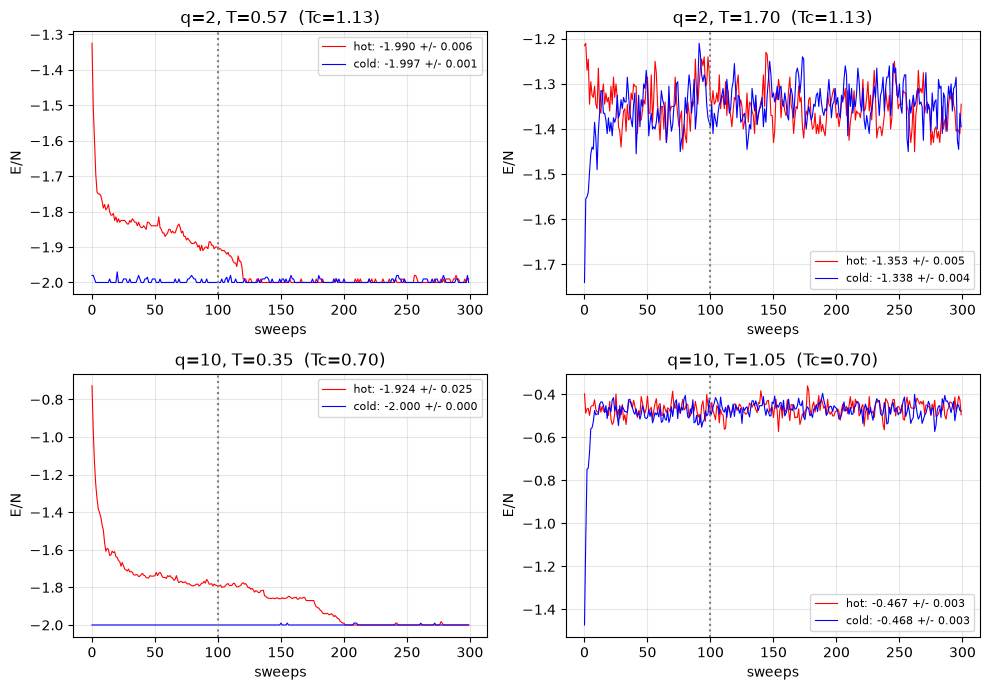

In [3]:
np.random.seed(4) # so plot has dependable behavior for presentation
n = 1
plt.figure(figsize=(10, 7)) # keeps plotted area large
for q in [2, 10]: # compare spin
    for T in [0.5 * Tc(q), 1.5 * Tc(q)]:       # one below Tc, one above
        plt.subplot(2, 2, n); n += 1 # n gives plot posn in 2x2 grid
        for hot, c in [(True, 'red'), (False, 'blue')]: # color the data for hot and cold
            mean, err, hist = full_sim(L=20, q=q, T=T, sweeps=300, burn=100, hot=hot, blocks=12)
            # color=c keeps hot/cold red/blue from above, lw=0.8 makes lines readable
            plt.plot(hist, color=c, lw=0.8, label=f'{"hot" if hot else "cold"}: {mean:.3f} +/- {err:.3f}')
        plt.axvline(100, color='grey', ls=':')   # burn line: averaging starts after (burn=100)
        plt.title(f'q={q}, T={T:.2f}  (Tc={Tc(q):.2f})')
        plt.xlabel('sweeps'); plt.ylabel('E/N')
        plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Onsager: Expected Energies at q = 2
Onsager equation for q=2 square lattice Ising model (spins converted from Potts(1,2) to Ising vars(-1, +1)) E/N values given T. K represents elliptical function with value changing based on T.

$$u(T) = -\coth\left(\frac{1}{T}\right) \left[ 1 + \frac{1}{\pi} \left(2\tanh^2\left(\frac{1}{T}\right) - 1\right) K\left( \frac{1\sinh\left(\frac{1}{T}\right)}{\cosh^2\left(\frac{1}{T}\right)} \right) \right]$$


<img src="equation_images/onsager_116.png" width="400">
<img src="equation_images/onsager_118a.png" width="400">
Onsager paper (1944)

In [ ]:
# expected Onsager equation values, also used in heabath_f.py file.
print('For q = 2:')
# based on using Kronecker delta, 2N nearest-neighbor bonds to simplify:
for T in [0.1, 0.5, 1.0, 2.0]:
    b = 1.0 / T
    k = 2 * np.sinh(b) / np.cosh(b)**2
    k1 = 2 * np.tanh(b)**2 - 1
    # ellipk is used for the integral (see 118a in paper)
    u = -(1 / np.tanh(b)) * (1 + (2 / np.pi) * k1 * ellipk(k**2)) # see 116 in paper
    print(f"T = {T:3.1f} | E/N = {-1 + 0.5 * u:.4f}")